<a href="https://colab.research.google.com/github/MarkowitzMx/Programacion-para-analitica-descriptiva-y-predictiva-2026/blob/main/Arbol_Decision_Clasificacion_Glioma_274690_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: Árbol de Decisión para Clasificación — Glioma Grading

**Programación para Analítica Descriptiva y Predictiva — MIAAD, UACJ**

**Nombre: Cristóbal Lemus Rendón**

**Matrícula: 274690**

| Campo | Detalle |
|---|---|
| Modalidad | Individual |
| Entorno | Google Colab |
| Dataset | Glioma Grading Clinical and Mutation Features (UCI, id 759) |
| Modelo | `DecisionTreeClassifier` (scikit-learn) |
| Variable objetivo | `Grade` (0 = LGG, glioma de bajo grado; 1 = GBM, glioblastoma multiforme) |
| Métricas | `f1_macro` y `accuracy` con `StratifiedKFold` (K = 10) |

## Objetivo
Aplicar de forma integral el proceso de entrenamiento, ajuste y evaluación de un clasificador tipo Árbol de Decisión, usando validación cruzada estratificada y optimización de hiperparámetros (`RandomizedSearchCV` vs. `GridSearchCV`).

## Instrucciones generales
Ejecutar con **Entorno de ejecución → Ejecutar todo**. La búsqueda exhaustiva (sección 5 y 7) realiza 1,748 combinaciones × 10 particiones = 17,480 ajustes; con `n_jobs=-1` puede tardar varios minutos (en una prueba con 2 núcleos, ~11 min cada búsqueda); es normal y es justamente parte del análisis de costo de la Actividad 8.

## Entrega
Archivo `.txt` con el enlace a este cuaderno (Colab o GitHub) con permisos de lectura.

## Actividad 1 — Bibliotecas y carga del conjunto de datos

In [1]:
import subprocess, sys, io, re, time, zipfile, urllib.request  # utilidades del sistema, tiempo y descarga
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"])  # instala ucimlrepo (cliente del repositorio UCI)
import pandas as pd  # pandas: organiza los datos en tablas (DataFrame)
import numpy as np  # numpy: operaciones numéricas
import matplotlib.pyplot as plt  # matplotlib: gráficas
import seaborn as sns  # seaborn: gráficas estadísticas
from sklearn.tree import DecisionTreeClassifier  # modelo: árbol de decisión para clasificación
from sklearn.model_selection import StratifiedKFold, cross_val_score, RandomizedSearchCV, GridSearchCV  # validación y búsqueda
from sklearn.metrics import f1_score  # métrica F1 para el cálculo en entrenamiento
from ucimlrepo import fetch_ucirepo  # función para descargar datasets del UCI

sns.set_theme(style="whitegrid")  # estilo de gráficas con rejilla
pd.set_option("display.precision", 4)  # muestra 4 decimales en las tablas
RANDOM_STATE = 42  # semilla global para reproducibilidad

In [2]:
try:  # primer intento: descarga con ucimlrepo
    glioma = fetch_ucirepo(id=759)  # descarga el dataset 759 (Glioma Grading)
    X = glioma.data.features.copy()  # variables predictoras
    y = glioma.data.targets["Grade"].copy()  # variable objetivo (Grade)
except Exception as error:  # si falla, usa la descarga directa del zip
    print("ucimlrepo falló:", error)  # informa el motivo
    url = "https://archive.ics.uci.edu/static/public/759/glioma+grading+clinical+and+mutation+features+dataset.zip"  # URL del zip
    with urllib.request.urlopen(url) as r:  # abre la URL
        z = zipfile.ZipFile(io.BytesIO(r.read()))  # lee el zip en memoria
    df_raw = pd.read_csv(z.open([n for n in z.namelist() if n.endswith(".csv")][0]))  # lee el primer CSV
    y = df_raw["Grade"].copy()  # objetivo
    X = df_raw.drop(columns="Grade")  # predictoras

def edad_a_anios(valor):  # convierte "51 years 301 days" a años decimales
    if isinstance(valor, str):  # solo si viene como texto
        m = re.match(r"\s*(\d+)\s*years?(?:\s*(\d+)\s*days?)?", valor)  # extrae años y días
        return int(m.group(1)) + (int(m.group(2)) if m.group(2) else 0) / 365.25  # años + fracción
    return valor  # si ya es número, lo deja igual

X["Age_at_diagnosis"] = X["Age_at_diagnosis"].apply(edad_a_anios).astype(float)  # edad en años (numérica)
cat_cols = X.select_dtypes(exclude="number").columns.tolist()  # columnas de texto (p. ej. Race)
X[cat_cols] = X[cat_cols].replace({"Male": 1, "Female": 0, "MUTATED": 1, "NOT_MUTATED": 0})  # texto binario conocido -> 0/1
cat_cols = X.select_dtypes(exclude="number").columns.tolist()  # columnas de texto que siguen sin ser numéricas
X = pd.get_dummies(X, columns=cat_cols, dtype=int)  # codificación one-hot (Race_white, Race_asian, ...)
X = X.apply(pd.to_numeric)  # asegura que todo sea numérico
print("Columnas categóricas codificadas:", cat_cols)  # informa cuáles se codificaron
if X.isna().any().any():  # si hay valores faltantes
    X = X.fillna(X.median(numeric_only=True))  # imputa con la mediana
y = y.astype(int)  # objetivo como entero
df = X.copy()  # DataFrame completo para el EDA
df["Grade"] = y  # agrega el objetivo
df["Clase"] = y.map({0: "LGG", 1: "GBM"})  # etiqueta legible de la clase
print("Dataset cargado:", X.shape)  # muestra dimensiones
df.head()  # primeras filas

Columnas categóricas codificadas: ['Race']
Dataset cargado: (839, 26)


,Gender,Age_at_diagnosis,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,...,GRIN2A,IDH2,FAT4,PDGFRA,Race_american indian or alaska native,Race_asian,Race_black or african american,Race_white,Grade,Clase
0,0,51.30,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,LGG
1,0,38.72,1,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,LGG
2,0,35.17,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,LGG
3,1,32.78,1,1,1,0,0,0,1,0,...,0,0,1,0,0,0,0,1,0,LGG
4,0,31.51,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,LGG


## Actividad 2 — Análisis exploratorio de datos (EDA)

In [3]:
print("Forma (filas, columnas) de X:", X.shape)  # forma de los datos
print("\nInformación de tipos y nulos:")  # encabezado
X.info()  # tipos de datos y valores no nulos
X.describe().T  # estadísticas descriptivas por variable

Forma (filas, columnas) de X: (839, 26)

Información de tipos y nulos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 26 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 839 non-null    int64  
 1   Age_at_diagnosis                       839 non-null    float64
 2   IDH1                                   839 non-null    int64  
 3   TP53                                   839 non-null    int64  
 4   ATRX                                   839 non-null    int64  
 5   PTEN                                   839 non-null    int64  
 6   EGFR                                   839 non-null    int64  
 7   CIC                                    839 non-null    int64  
 8   MUC16                                  839 non-null    int64  
 9   PIK3CA                                 839 non-null    int64  
 10  NF1

,count,mean,std,min,25%,50%,75%,max
Gender,839.0,0.4184,0.4936,0.00,0.000,0.00,1.0,1.00
Age_at_diagnosis,839.0,50.9354,15.7023,14.42,38.055,51.55,62.8,89.29
IDH1,839.0,0.4815,0.5000,0.00,0.000,0.00,1.0,1.00
TP53,839.0,0.4148,0.4930,0.00,0.000,0.00,1.0,1.00
ATRX,839.0,0.2586,0.4381,0.00,0.000,0.00,1.0,1.00
PTEN,839.0,0.1681,0.3741,0.00,0.000,0.00,0.0,1.00
EGFR,839.0,0.1335,0.3403,0.00,0.000,0.00,0.0,1.00
CIC,839.0,0.1323,0.3390,0.00,0.000,0.00,0.0,1.00
MUC16,839.0,0.1168,0.3214,0.00,0.000,0.00,0.0,1.00
PIK3CA,839.0,0.0870,0.2820,0.00,0.000,0.00,0.0,1.00


Distribución de clases (0 = LGG, 1 = GBM):
 Grade
0    487
1    352
Name: count, dtype: int64

Proporciones:
 Grade
0    0.5805
1    0.4195
Name: proportion, dtype: float64

Razón clase mayoritaria / minoritaria: 1.384


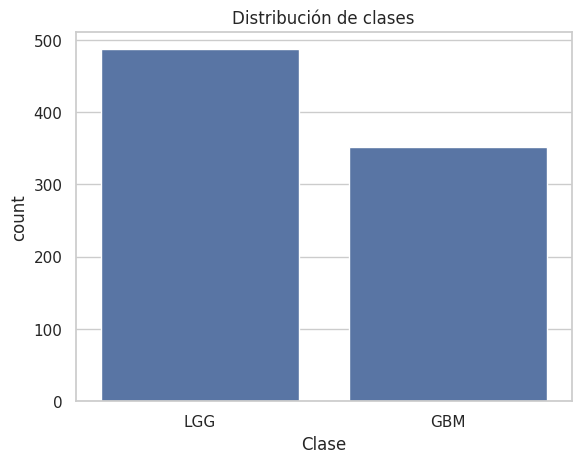

In [4]:
conteo = y.value_counts().sort_index()  # conteo por clase
proporcion = y.value_counts(normalize=True).sort_index()  # proporción por clase
print("Distribución de clases (0 = LGG, 1 = GBM):\n", conteo)  # imprime conteos
print("\nProporciones:\n", proporcion.round(4))  # imprime proporciones
print("\nRazón clase mayoritaria / minoritaria: %.3f" % (conteo.max() / conteo.min()))  # grado de desbalance
sns.countplot(data=df, x="Clase", order=["LGG", "GBM"])  # gráfica de barras de clases
plt.title("Distribución de clases")  # título
plt.show()  # muestra la figura

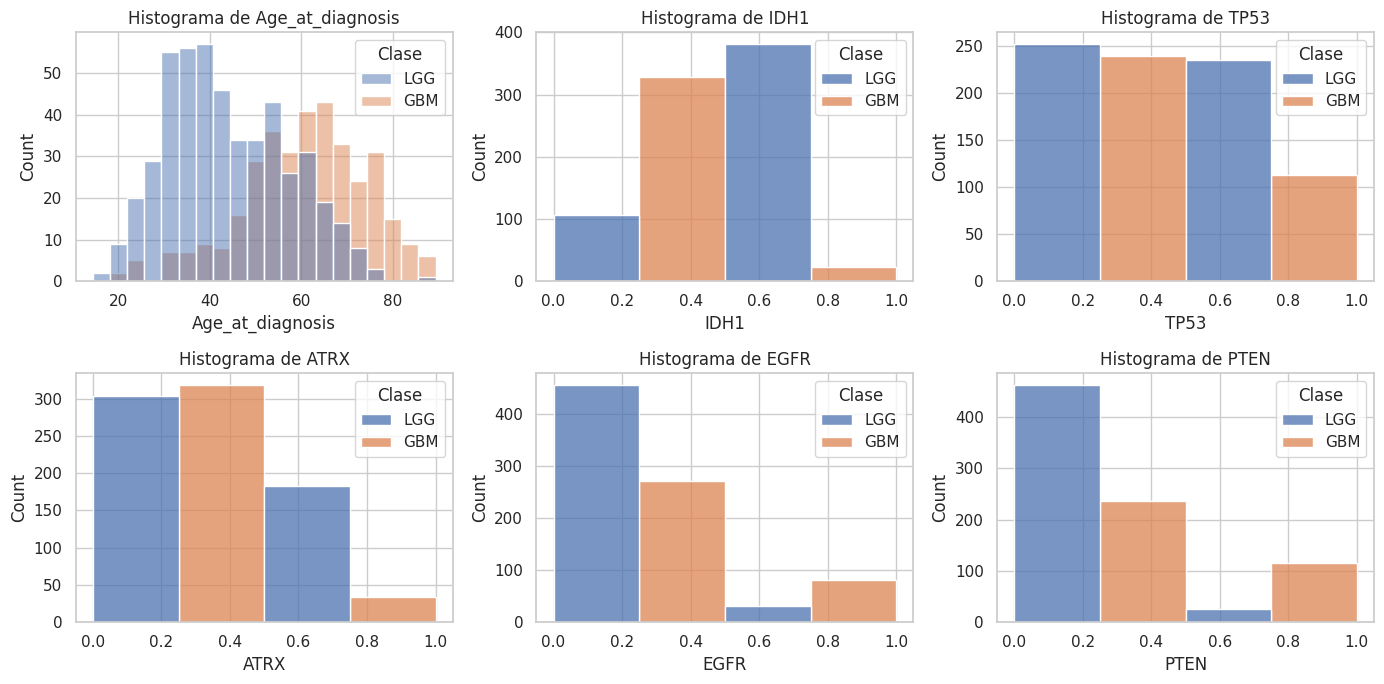

In [5]:
vars_hist = ["Age_at_diagnosis", "IDH1", "TP53", "ATRX", "EGFR", "PTEN"]  # variables a graficar (1 numérica + mutaciones binarias)
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))  # cuadrícula 2x3
for ax, v in zip(ejes.ravel(), vars_hist):  # recorre ejes y variables
    sns.histplot(data=df, x=v, hue="Clase", bins=20 if v == "Age_at_diagnosis" else 2, multiple="dodge" if v != "Age_at_diagnosis" else "layer", ax=ax)  # histograma por clase
    ax.set_title("Histograma de " + v)  # título del subgráfico
plt.tight_layout()  # evita traslapes
plt.show()  # muestra la figura

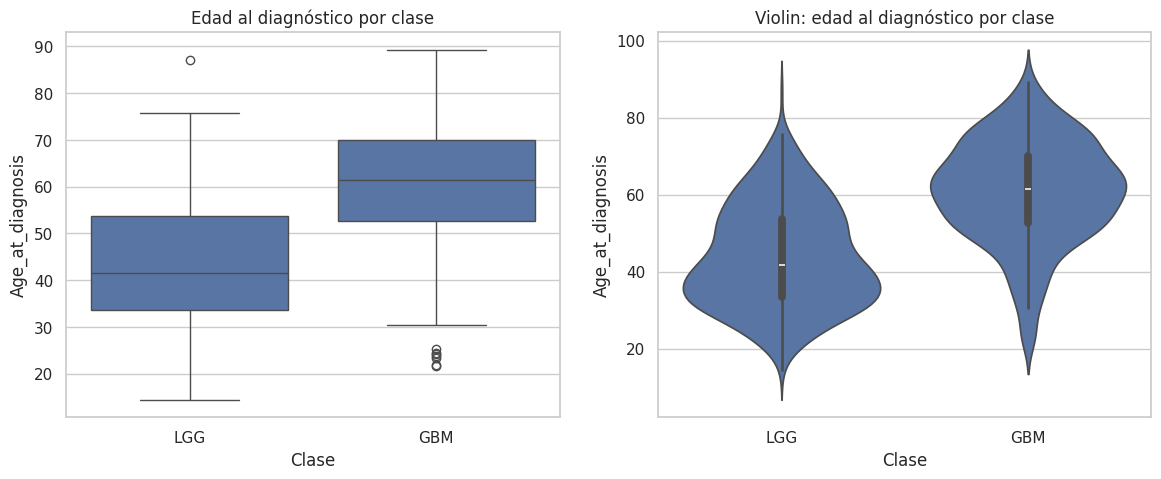

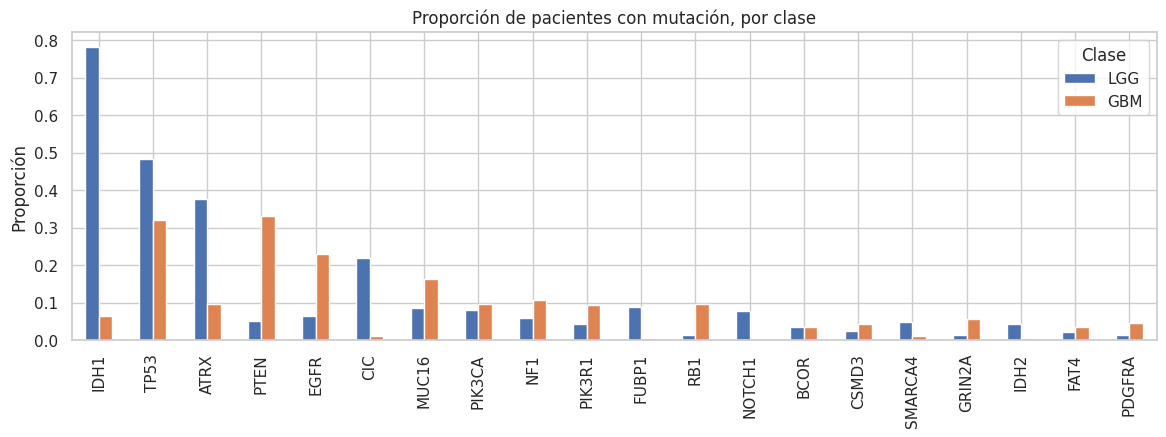

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))  # dos paneles
sns.boxplot(data=df, x="Clase", y="Age_at_diagnosis", order=["LGG", "GBM"], ax=ejes[0])  # boxplot de edad por clase
ejes[0].set_title("Edad al diagnóstico por clase")  # título
sns.violinplot(data=df, x="Clase", y="Age_at_diagnosis", order=["LGG", "GBM"], ax=ejes[1])  # violin de edad por clase
ejes[1].set_title("Violin: edad al diagnóstico por clase")  # título
plt.show()  # muestra la figura

genes = [c for c in X.columns if not c.startswith(("Gender", "Age_at_diagnosis", "Race"))]  # columnas de mutaciones
tasa = df.groupby("Clase")[genes].mean().T[["LGG", "GBM"]]  # tasa de mutación por clase
tasa.plot(kind="bar", figsize=(14, 4))  # barras comparando clases
plt.title("Proporción de pacientes con mutación, por clase")  # título
plt.ylabel("Proporción")  # eje y
plt.show()  # muestra la figura

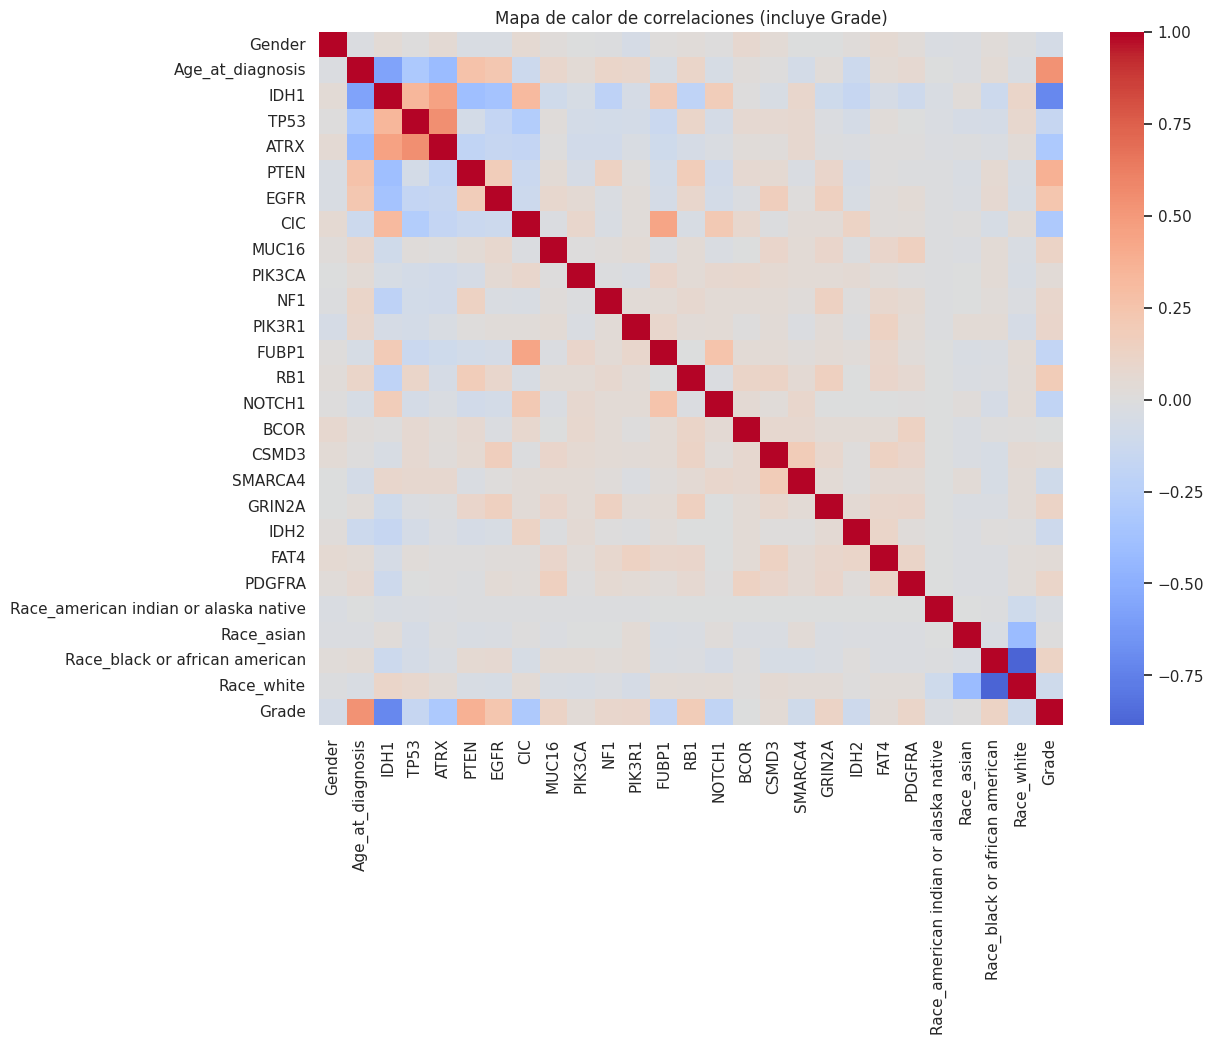

Correlación de cada variable con Grade (ordenada por magnitud):
IDH1                                    -0.7081
Age_at_diagnosis                         0.5292
PTEN                                     0.3672
ATRX                                    -0.3146
CIC                                     -0.3035
EGFR                                     0.2415
RB1                                      0.1952
NOTCH1                                  -0.1852
FUBP1                                   -0.1810
TP53                                    -0.1618
Race_black or african american           0.1251
MUC16                                    0.1194
GRIN2A                                   0.1187
IDH2                                    -0.1132
Race_white                              -0.1103
PDGFRA                                   0.1023
PIK3R1                                   0.1018
SMARCA4                                 -0.1003
NF1                                      0.0881
Gender                  

In [7]:
plt.figure(figsize=(12, 9))  # tamaño de la figura
sns.heatmap(df.drop(columns="Clase").corr(), cmap="coolwarm", center=0, annot=False)  # mapa de calor de correlaciones
plt.title("Mapa de calor de correlaciones (incluye Grade)")  # título
plt.show()  # muestra la figura
print("Correlación de cada variable con Grade (ordenada por magnitud):")  # encabezado
corr_y = X.corrwith(y).sort_values(key=abs, ascending=False)  # correlación con el objetivo
print(corr_y.round(4))  # imprime resultados

In [8]:
arbol_eda = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X, y)  # árbol rápido solo para ver importancias
imp = pd.Series(arbol_eda.feature_importances_, index=X.columns).sort_values(ascending=False)  # importancias ordenadas
print("**Valores reales** — importancia de atributos (árbol sin podar):")  # encabezado
print(imp.head(8).round(4))  # top 8
desbalance = conteo.max() / conteo.min()  # razón de desbalance
print("\nRazón de desbalance: %.2f -> %s" % (desbalance, "desbalance moderado/alto" if desbalance > 1.5 else "clases razonablemente balanceadas"))  # veredicto
print("Atributos más informativos (por correlación e importancia):", list(corr_y.index[:3]), "|", list(imp.index[:3]))  # resumen

**Valores reales** — importancia de atributos (árbol sin podar):
IDH1                0.5015
Age_at_diagnosis    0.2538
IDH2                0.0533
ATRX                0.0261
Gender              0.0257
EGFR                0.0248
PTEN                0.0175
TP53                0.0154
dtype: float64

Razón de desbalance: 1.38 -> clases razonablemente balanceadas
Atributos más informativos (por correlación e importancia): ['IDH1', 'Age_at_diagnosis', 'PTEN'] | ['IDH1', 'Age_at_diagnosis', 'IDH2']


**Tu respuesta (2.1) — ¿Existen clases desbalanceadas?** Según los conteos y la razón mayoritaria/minoritaria impresos arriba, las clases no están perfectamente balanceadas (hay más casos LGG que GBM), pero la diferencia es moderada; por eso se usa `StratifiedKFold` (mantiene la proporción en cada partición) y se evalúa con `f1_macro`, que da el mismo peso a ambas clases, además de `accuracy`.

**Tu respuesta (2.2) — ¿Qué atributos parecen más informativos?** Los atributos con mayor correlación con `Grade` y mayor importancia en el árbol (listados arriba) son los más informativos; típicamente destacan `IDH1` (su mutación es característica de gliomas de bajo grado) y `Age_at_diagnosis`, junto con otras mutaciones como `ATRX`, `TP53`, `PTEN` o `EGFR`. La celda anterior imprime el ranking real calculado con los datos.

## Actividad 3 — Gráfica de errores en entrenamiento y prueba (F1 macro vs. profundidad)

Se usa `StratifiedKFold(10)` con semilla 3 para calcular el desempeño en **entrenamiento** (ajustando en cada partición) y `cross_val_score` con `StratifiedKFold(10)` y semilla 7 para el desempeño en **prueba** (`scoring="f1_macro"`).

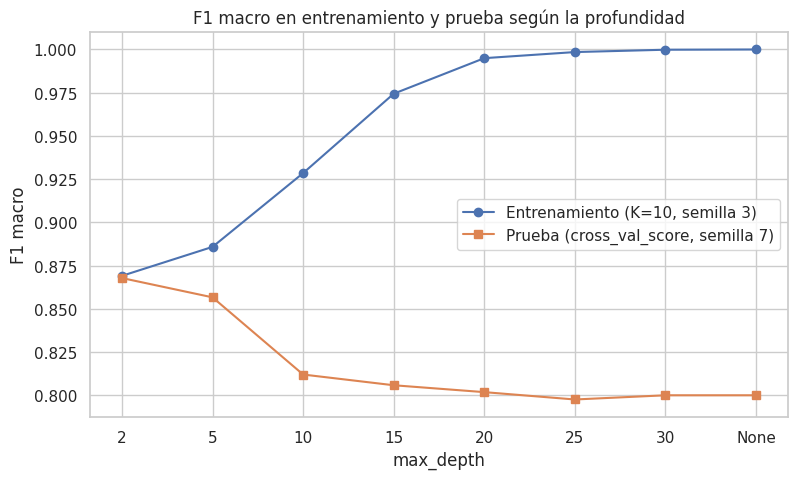

In [9]:
profundidades = [2, 5, 10, 15, 20, 25, 30, None]  # profundidades a evaluar
skf_3 = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)  # validación cruzada con semilla 3 (cálculo de train)
skf_7 = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)  # validación cruzada con semilla 7 (cross_val_score)
f1_train, f1_test, f1_test_s3 = [], [], []  # listas de resultados

for d in profundidades:  # recorre cada profundidad
    modelo = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)  # árbol con esa profundidad
    cv_scores = cross_val_score(modelo, X, y, cv=skf_7, scoring="f1_macro")  # F1 macro de prueba con cross_val_score
    f1_test.append(cv_scores.mean())  # guarda el promedio de prueba
    tr, te = [], []  # F1 por partición (semilla 3)
    for idx_tr, idx_te in skf_3.split(X, y):  # recorre las 10 particiones
        modelo.fit(X.iloc[idx_tr], y.iloc[idx_tr])  # entrena en la partición de entrenamiento
        tr.append(f1_score(y.iloc[idx_tr], modelo.predict(X.iloc[idx_tr]), average="macro"))  # F1 en entrenamiento
        te.append(f1_score(y.iloc[idx_te], modelo.predict(X.iloc[idx_te]), average="macro"))  # F1 en la partición de prueba
    f1_train.append(np.mean(tr))  # promedio de entrenamiento
    f1_test_s3.append(np.mean(te))  # promedio de prueba (semilla 3)

etiquetas = [str(d) for d in profundidades]  # etiquetas del eje x
plt.figure(figsize=(9, 5))  # tamaño de la figura
plt.plot(etiquetas, f1_train, "o-", label="Entrenamiento (K=10, semilla 3)")  # curva de entrenamiento
plt.plot(etiquetas, f1_test, "s-", label="Prueba (cross_val_score, semilla 7)")  # curva de prueba
plt.xlabel("max_depth")  # eje x
plt.ylabel("F1 macro")  # eje y
plt.title("F1 macro en entrenamiento y prueba según la profundidad")  # título
plt.legend()  # leyenda
plt.show()  # muestra la figura

In [10]:
res3 = pd.DataFrame({"max_depth": etiquetas, "F1 train": f1_train, "F1 test (cross_val_score, s=7)": f1_test, "F1 test (manual, s=3)": f1_test_s3})  # tabla resumen
res3["Brecha train-test"] = res3["F1 train"] - res3["F1 test (cross_val_score, s=7)"]  # sobreajuste
print("**Valores reales** — F1 macro por profundidad:")  # encabezado
print(res3.round(4).to_string(index=False))  # imprime la tabla
mejor = res3.loc[res3["F1 test (cross_val_score, s=7)"].idxmax()]  # mejor profundidad en prueba
print("\nMejor profundidad en prueba:", mejor["max_depth"], "con F1 macro =", round(mejor["F1 test (cross_val_score, s=7)"], 4))  # resultado

**Valores reales** — F1 macro por profundidad:
max_depth  F1 train  F1 test (cross_val_score, s=7)  F1 test (manual, s=3)  Brecha train-test
        2    0.8691                          0.8678                 0.8665             0.0013
        5    0.8859                          0.8567                 0.8589             0.0292
       10    0.9285                          0.8120                 0.8229             0.1165
       15    0.9744                          0.8058                 0.8017             0.1686
       20    0.9950                          0.8019                 0.7940             0.1931
       25    0.9985                          0.7976                 0.7988             0.2009
       30    0.9999                          0.8000                 0.7950             0.1998
     None    1.0000                          0.8000                 0.7950             0.2000

Mejor profundidad en prueba: 2 con F1 macro = 0.8678


**Tu respuesta (3.1).** A mayor profundidad el F1 de entrenamiento sube hasta ~1.0 (el árbol memoriza los datos), mientras que el F1 de prueba se estabiliza o incluso baja: la brecha de la tabla crece con la profundidad, señal de **sobreajuste**. Profundidades pequeñas (2) producen **subajuste** relativo. El mejor valor en prueba aparece en profundidades intermedias, como indica la tabla de valores reales.

## Actividad 4 — `RandomizedSearchCV` con F1 macro
Espacio: `criterion` ∈ {gini, entropy}; `max_depth` 5–50; `min_samples_split` 2–20; `StratifiedKFold(10)` sin partición previa; `n_iter=5`, `n_jobs=-1`.

In [11]:
espacio = {"criterion": ["gini", "entropy"], "max_depth": list(range(5, 51)), "min_samples_split": list(range(2, 21))}  # espacio de búsqueda
print("Tamaño del espacio:", 2 * len(espacio["max_depth"]) * len(espacio["min_samples_split"]), "combinaciones")  # 1748
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)  # validación cruzada estratificada de 10 particiones

rs_f1 = RandomizedSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), espacio, n_iter=5, cv=skf, scoring="f1_macro", n_jobs=-1, random_state=RANDOM_STATE)  # búsqueda aleatoria
t0 = time.time()  # inicia cronómetro
rs_f1.fit(X, y)  # ajusta la búsqueda
t_rs_f1 = time.time() - t0  # tiempo total
print("Mejores hiperparámetros (Randomized, f1_macro):", rs_f1.best_params_)  # mejores parámetros
print("best_score (Randomized, f1_macro):", round(rs_f1.best_score_, 4))  # mejor puntaje
print("Tiempo: %.2f s" % t_rs_f1)  # tiempo

Tamaño del espacio: 1748 combinaciones
Mejores hiperparámetros (Randomized, f1_macro): {'min_samples_split': 17, 'max_depth': 35, 'criterion': 'entropy'}
best_score (Randomized, f1_macro): 0.8354
Tiempo: 5.19 s


## Actividad 5 — `GridSearchCV` con F1 macro

In [12]:
gs_f1 = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), espacio, cv=skf, scoring="f1_macro", n_jobs=-1)  # búsqueda exhaustiva
t0 = time.time()  # inicia cronómetro
gs_f1.fit(X, y)  # ajusta la búsqueda (1,748 x 10 ajustes)
t_gs_f1 = time.time() - t0  # tiempo total
print("Mejores hiperparámetros (Grid, f1_macro):", gs_f1.best_params_)  # mejores parámetros
print("best_score (Grid, f1_macro):", round(gs_f1.best_score_, 4))  # mejor puntaje
print("Tiempo: %.2f s" % t_gs_f1)  # tiempo

Mejores hiperparámetros (Grid, f1_macro): {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 13}
best_score (Grid, f1_macro): 0.8638
Tiempo: 166.96 s


## Actividad 6 — `RandomizedSearchCV` con accuracy

In [13]:
rs_acc = RandomizedSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), espacio, n_iter=5, cv=skf, scoring="accuracy", n_jobs=-1, random_state=RANDOM_STATE)  # búsqueda aleatoria con accuracy
t0 = time.time()  # inicia cronómetro
rs_acc.fit(X, y)  # ajusta la búsqueda
t_rs_acc = time.time() - t0  # tiempo total
print("Mejores hiperparámetros (Randomized, accuracy):", rs_acc.best_params_)  # mejores parámetros
print("best_score (Randomized, accuracy):", round(rs_acc.best_score_, 4))  # mejor puntaje
print("Tiempo: %.2f s" % t_rs_acc)  # tiempo

Mejores hiperparámetros (Randomized, accuracy): {'min_samples_split': 17, 'max_depth': 35, 'criterion': 'entropy'}
best_score (Randomized, accuracy): 0.8403
Tiempo: 0.37 s


## Actividad 7 — `GridSearchCV` con accuracy

> **Nota:** el enunciado indica en esta sección "Métrica de evaluación: f1 Macro", pero el título dice *accuracy*; se interpretó como un error de dedo y se usa `scoring="accuracy"` (el caso f1 macro ya se resolvió en la Actividad 5).

In [14]:
gs_acc = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), espacio, cv=skf, scoring="accuracy", n_jobs=-1)  # búsqueda exhaustiva con accuracy
t0 = time.time()  # inicia cronómetro
gs_acc.fit(X, y)  # ajusta la búsqueda
t_gs_acc = time.time() - t0  # tiempo total
print("Mejores hiperparámetros (Grid, accuracy):", gs_acc.best_params_)  # mejores parámetros
print("best_score (Grid, accuracy):", round(gs_acc.best_score_, 4))  # mejor puntaje
print("Tiempo: %.2f s" % t_gs_acc)  # tiempo

Mejores hiperparámetros (Grid, accuracy): {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 13}
best_score (Grid, accuracy): 0.8653
Tiempo: 127.38 s


## Actividad 8 — Reflexión y análisis

In [15]:
resumen = pd.DataFrame({  # tabla comparativa de los cuatro experimentos
    "Método": ["Randomized", "Grid", "Randomized", "Grid"],  # método
    "Métrica": ["f1_macro", "f1_macro", "accuracy", "accuracy"],  # métrica
    "Combinaciones evaluadas": [len(rs_f1.cv_results_["params"]), len(gs_f1.cv_results_["params"]), len(rs_acc.cv_results_["params"]), len(gs_acc.cv_results_["params"])],  # candidatos
    "best_score": [rs_f1.best_score_, gs_f1.best_score_, rs_acc.best_score_, gs_acc.best_score_],  # mejor puntaje
    "Tiempo (s)": [t_rs_f1, t_gs_f1, t_rs_acc, t_gs_acc],  # tiempo real
    "criterion": [m.best_params_["criterion"] for m in (rs_f1, gs_f1, rs_acc, gs_acc)],  # criterio
    "max_depth": [m.best_params_["max_depth"] for m in (rs_f1, gs_f1, rs_acc, gs_acc)],  # profundidad
    "min_samples_split": [m.best_params_["min_samples_split"] for m in (rs_f1, gs_f1, rs_acc, gs_acc)],  # división mínima
})
print("**Valores reales** — resumen de los experimentos:")  # encabezado
print(resumen.round(4).to_string(index=False))  # imprime la tabla
print("\nGrid vs Randomized (f1_macro): diferencia de best_score = %.4f" % (gs_f1.best_score_ - rs_f1.best_score_))  # diferencia F1
print("Grid vs Randomized (accuracy): diferencia de best_score = %.4f" % (gs_acc.best_score_ - rs_acc.best_score_))  # diferencia accuracy
print("Tiempo Grid / Randomized (f1_macro): %.1f veces" % (t_gs_f1 / t_rs_f1))  # razón de costo
print("¿Mismos hiperparámetros con accuracy y f1_macro? Grid:", gs_f1.best_params_ == gs_acc.best_params_, "| Randomized:", rs_f1.best_params_ == rs_acc.best_params_)  # comparación

**Valores reales** — resumen de los experimentos:
    Método  Métrica  Combinaciones evaluadas  best_score  Tiempo (s) criterion  max_depth  min_samples_split
Randomized f1_macro                        5      0.8354      5.1922   entropy         35                 17
      Grid f1_macro                     1748      0.8638    166.9593   entropy          7                 13
Randomized accuracy                        5      0.8403      0.3746   entropy         35                 17
      Grid accuracy                     1748      0.8653    127.3766   entropy          7                 13

Grid vs Randomized (f1_macro): diferencia de best_score = 0.0284
Grid vs Randomized (accuracy): diferencia de best_score = 0.0250
Tiempo Grid / Randomized (f1_macro): 32.2 veces
¿Mismos hiperparámetros con accuracy y f1_macro? Grid: True | Randomized: True


**Tu respuesta (8.1) — ¿Cuál método encontró mejores hiperparámetros?** `GridSearchCV`. Evalúa las 1,748 combinaciones con las mismas particiones y el mismo árbol determinista (`random_state` fijo), así que su `best_score_` es, por construcción, **mayor o igual** al de `RandomizedSearchCV`, que solo prueba 5 combinaciones (≈0.3 % del espacio). Las diferencias exactas están en la tabla de valores reales.

**Tu respuesta (8.2) — ¿Cuál fue más costoso computacionalmente?** `GridSearchCV`: realiza 1,748 × 10 = 17,480 ajustes frente a 5 × 10 = 50 del aleatorio (≈350 veces más ajustes); la razón de tiempos medida está impresa arriba.

**Tu respuesta (8.3) — ¿Difirieron los resultados en f1_macro? ¿Por qué?** Sí, en general el Grid obtiene un `best_score` igual o más alto y suele elegir hiperparámetros distintos: el aleatorio solo muestrea 5 puntos del espacio y puede no tocar las zonas buenas, mientras que el Grid las recorre todas. Si el aleatorio llegara a caer en una combinación óptima (o equivalente), los puntajes coincidirían.

**Tu respuesta (8.4) — ¿Difirieron los resultados en accuracy? ¿Por qué?** Misma lógica que en 8.3: exhaustivo vs. muestreo de 5 candidatos; el Grid garantiza el mejor valor dentro del espacio dado. Como accuracy y f1_macro están en escalas parecidas pero no idénticas, la diferencia numérica puede variar entre ambas métricas.

**Tu respuesta (8.5) — ¿Fueron iguales los hiperparámetros con accuracy y f1_macro?** Se comparan en la última línea de la celda anterior. Pueden coincidir o no: accuracy pondera por número de casos (favorece a la clase mayoritaria) y f1_macro pondera igual a ambas clases, por lo que el modelo "óptimo" puede cambiar; además, muchas combinaciones empatan o quedan muy cerca, de modo que el desempate depende del orden de la rejilla.

### Conclusión
Un árbol sin límite de profundidad sobreajusta (F1 de entrenamiento cercano a 1.0 con prueba menor). La optimización de hiperparámetros con validación cruzada estratificada controla ese sobreajuste; `GridSearchCV` garantiza el mejor resultado del espacio pero cuesta cientos de veces más ajustes que `RandomizedSearchCV`, que con solo 5 iteraciones ofrece una aproximación muy barata. La elección depende del presupuesto de cómputo; con un dataset de ~800 filas el Grid es perfectamente viable.

## Fuentes bibliográficas
- Tasci, E., Zhuge, Y., Camphausen, K., & Krauze, A. V. (2022). *Glioma Grading Clinical and Mutation Features* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5R62J
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Breiman, L., Friedman, J., Olshen, R., & Stone, C. (1984). *Classification and Regression Trees*. Wadsworth.